This notebook reproduces Fig. 6.

**(a)-(b) Basis of Landau-Zener pulses.** We use the pulse shapes obtained by solving the Landau-Zener problem with $(\alpha, \beta)$ hypergeometries (see `Fig02-LZ.ipynb`), given by $f_i(\tau)$, with $\tau=t/t_\mathrm{f}\in\left[0,1\right]$. However, the basis of functions is overcomplete. To obtain the minimal subset of basis elements $\tilde{f}_i(\tau)$, we perform a QR decomposition with pivoting of the Gram matrix, keeping the elements with $|R_{ii}|>10^{-10}$.

A general function $g(\tau)$ can be approximated as
$$
g(\tau)\approx g'(\tau)=\sum_i c_i\tilde{f}_i(\tau).
$$
Since our basis is non-orthogonal, the coefficients $c_i$ can be obtained by solving the linear system
$$
\tilde{G} \vec{c}= \vec{b},
$$
where $\tilde{G}_{ij} = \langle \tilde{f}_i|\tilde{f}_j\rangle$ are the components of the Gram matrix, and $b_i = \langle g|\tilde{f_i}\rangle$. As a proof of concept, we use the cubic function $g(\tau) = -10 + 100 \tau -240 \tau^2 + 160\tau^3$.

**(c)-(d) $\Lambda$-system.** The Hamiltonian for a $\Lambda$-system is given by
$$
\hat{H}_\Lambda(t) =
\begin{pmatrix}
    0 & \tau_1 & 0 \\
    \tau_1 & 0 & \tau_2 \\
    0 & \tau_2 & \varepsilon(t) \\
\end{pmatrix},
$$
where $\tau_1$ controls the position of the anticrossings, located at $\varepsilon= \pm \tau_1$, and $\tau_2$ controls the minimum gap between the first excited state and the other two eigenstates. The energies $\varepsilon$, $\tau_1$, and $\tau_2$ are given in arbitrary units. We compute the error between the pulses obtained by directly solving the $(\alpha,\beta)$ hypergeometries, and the reconstruction of the pulses using the Landau-Zener basis. The pulses follow the first excited state, with $(\alpha,\beta)=(2,2)$. The error is defined as
$$
\mathcal{E} = \int_0^1d\tau|\varepsilon(\tau)-\varepsilon'(\tau)|,
$$
where $\varepsilon(\tau)$ is the exact pulse, and $\varepsilon'(\tau)$ its approximation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from parameterrun import parameterrun
from scipy.integrate import romb
from scipy.linalg import solve

from HQUAD_lib.hamiltonians import lambda_system
from HQUAD_lib.plotting_utils import add_labels
from HQUAD_lib.QUAD_utils import solve_LZ
from HQUAD_lib.utils import compute_error_basis_approx, independent_basis

# (a)-(b) Basis of Landau-Zener pulses

In [2]:
alphas_basis = np.linspace(
    -25, 60, 2001
)  # Decrease to speed up the calculation (with a larger error)
alphas_basis[0] = -np.inf
alphas_basis[-1] = np.inf

zs_sol = np.asarray(parameterrun(solve_LZ, "alpha", alphas_basis, beta=0, reduction=3))
s = np.linspace(0, 1, len(zs_sol[0]))
ds = s[1] - s[0]

independent_functions, G_independent = independent_basis(zs_sol, ds)
rank = len(independent_functions)
print(f"Number of elements in the basis: {rank}")

solve_LZ: [['alpha']]:   0%|          | 0/2001 [00:00<?, ?it/s]

Number of elements in the basis: 51


In [3]:
# Cubic function with g(0) = -10 and g(1) = 10
a0 = -10
a1 = 100
a2 = 60 - 3 * a1
a3 = -40 + 2 * a1
g = a0 + a1 * s + a2 * s**2 + a3 * s**3
print(f"g(tau) = {a0} + {a1} tau + {a2} tau^2 + {a3} tau^3")

# Coefficients of the linear combination, G c = b with b_i = <g|f_i>
b = romb(g * independent_functions, dx=ds, axis=-1)
c = solve(G_independent, b)
g_approx = c @ independent_functions

print(f"Reconstruction error: {np.sum(np.abs(g - g_approx)) * ds:.1e}")
print(f"Maximum deviation: {np.max(np.abs(g - g_approx)):.1e}")

g(tau) = -10 + 100 tau + -240 tau^2 + 160 tau^3
Reconstruction error: 1.2e-05
Maximum deviation: 1.0e-04


# (c)-(d) $\Lambda$-system

In [4]:
eps12 = 0
eps23_s = np.linspace(-40, 40, 2**15 + 1)

# Band structure
tau1 = 10
tau2 = 7

hypermatrix = np.array([lambda_system(eps12, eps23, tau1, tau2) for eps23 in eps23_s])
eigvalues = np.linalg.eigvalsh(hypermatrix)

In [5]:
partial_hamiltonian = np.array([lambda_system(0, 1, 0, 0) for _ in range(len(eps23_s))])

alpha = 2
beta = 2
adiabatic_state = 1

n_taus = 20  # Increase to enhance the resolution (400 values in the manuscript)
taus_1 = np.linspace(0.1, 10, n_taus)
taus_2 = np.linspace(0.1, 10, n_taus)


def compute_error(tau1: float, tau2: float) -> float:
    hypermatrix = np.array(
        [lambda_system(eps12, eps23, tau1, tau2) for eps23 in eps23_s]
    )
    eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

    return compute_error_basis_approx(
        eigvalues,
        eigmodes,
        eps23_s,
        partial_hamiltonian,
        alpha,
        beta,
        adiabatic_state,
        independent_functions,
        G_independent,
        limit_sup=np.inf,
        limit_inf=0,
    )


errors = np.asarray(
    parameterrun(compute_error, [["tau1"], ["tau2"]], [[taus_1], [taus_2]])
)
errors = errors.reshape((len(taus_1), len(taus_2)))

compute_error: [['tau1'], ['tau2']]:   0%|          | 0/400 [00:00<?, ?it/s]

# Plot

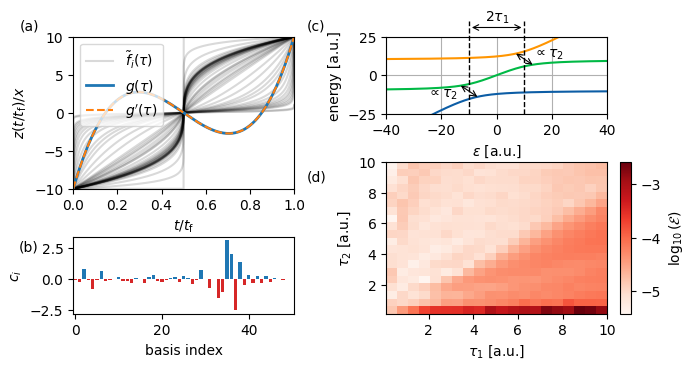

In [6]:
fig, axs = plt.subplot_mosaic(
    [["A", ".", "C", "."], ["A", ".", "D", "CD"], ["B", ".", "D", "CD"]],
    figsize=(7.2, 3.6),
    gridspec_kw={"height_ratios": [1, 0.35, 1], "width_ratios": [1, 0.3, 1, 0.05]},
)

# (a) Basis and approximation of the cubic function
for i, fun in enumerate(independent_functions):
    axs["A"].plot(
        s, fun, c="k", alpha=0.15, label=r"$\tilde{f}_i(\tau)$" if i == 0 else None
    )

axs["A"].plot(s, g, label=r"$g(\tau)$", linewidth=2, c="tab:blue")
axs["A"].plot(
    s, g_approx, "--", label=r"$g^\prime(\tau)$", c="tab:orange", linewidth=1.5
)

axs["A"].legend(frameon=True, framealpha=0.75, loc=0)
axs["A"].set_xlim(0, 1)
axs["A"].set_ylim(-10, 10)
axs["A"].set_xlabel(r"$t / t_\mathrm{f}$")
axs["A"].set_ylabel(r"$z(t / t_\mathrm{f}) / x$")

# (b) Coefficients
axs["B"].bar(np.arange(rank)[c > 0], c[c > 0])
axs["B"].bar(np.arange(rank)[c < 0], c[c < 0], color="tab:red")
axs["B"].set_ylabel(r"$c_i$")
axs["B"].set_xlabel("basis index")
axs["B"].set_xlim(-0.5, rank - 0.5)

# (c) Band structure of the Lambda-system
# Ground (blue), first excited (green, the adiabatic state) and second excited (orange) states
for eigvalue, color in zip(eigvalues.T, ["#0C5DA5", "#00B945", "#FF9500"]):
    axs["C"].plot(eps23_s, eigvalue, color=color)
axs["C"].grid()
axs["C"].set_xlim(min(eps23_s), max(eps23_s))
axs["C"].set_ylim(-25, 25)
axs["C"].set_xlabel(r"$\varepsilon$ [a.u.]")
axs["C"].set_ylabel("energy [a.u.]")

# Anticrossings at eps = +-tau_1, with gaps controlled by tau_2
for eps in (-tau1, tau1):
    axs["C"].axvline(eps, ymax=1.2, c="k", ls="--", lw=1, clip_on=False)
axs["C"].annotate(
    "",
    xy=(-tau1, 1.12),
    xytext=(tau1, 1.12),
    xycoords=axs["C"].get_xaxis_transform(),
    arrowprops={"arrowstyle": "<->", "lw": 0.8},
    annotation_clip=False,
)
axs["C"].text(
    0,
    1.14,
    r"$2\tau_1$",
    transform=axs["C"].get_xaxis_transform(),
    ha="center",
    va="bottom",
)

# Diagonal arrows between the eigenvalues next to each anticrossing
d_start, d_end = -3, 3
for eps_upper, eps_lower, (low, high), ha in [
    (tau1 + d_start, tau1 + d_end, (1, 2), "left"),
    (-tau1 - d_end, -tau1 - d_start, (0, 1), "right"),
]:
    e_high = np.interp(eps_upper, eps23_s, eigvalues[:, high])
    e_low = np.interp(eps_lower, eps23_s, eigvalues[:, low])
    axs["C"].annotate(
        "",
        xy=(eps_lower, e_low),
        xytext=(eps_upper, e_high),
        arrowprops={"arrowstyle": "<->", "lw": 0.8, "shrinkA": 0, "shrinkB": 0},
    )
    if ha == "left":
        eps_text, e_text = eps_lower, (e_low + e_high) / 2 + 3
    else:
        eps_text, e_text = eps_upper - 1, e_low + 0.35 * (e_high - e_low) - 1
    axs["C"].text(eps_text, e_text, r"$\propto \tau_2$", ha=ha, va="center")

# (d) Reconstruction error
im = axs["D"].imshow(
    np.log10(errors).T,
    origin="lower",
    aspect="auto",
    interpolation="none",
    cmap="Reds",
    extent=(min(taus_1), max(taus_1), min(taus_2), max(taus_2)),
)
plt.colorbar(im, cax=axs["CD"], label=r"$\log_{10}(\mathcal{E})$")

axs["D"].set_xlabel(r"$\tau_1$ [a.u.]")
axs["D"].set_ylabel(r"$\tau_2$ [a.u.]")

fig.subplots_adjust(hspace=0.8, wspace=0.1)
add_labels([axs["A"]] * 4, [[-0.2, 1.07], [-0.2, -0.38], [1.1, 1.07], [1.1, 0.08]])